# Funding Carry 01 — long spot / short perpetual funding harvest on Binance

Pre-registration: `discussions/Funding_Carry/001_claude_branch_preregistration.md`. Everything that decides the result is fixed in
`src/data_engineering/modeling/funding_carry.py` (`registration()` below).

- **Trade:** long $u$ spot, short $u$ USD-M perpetual ($u = 1/S_\text{entry}$), delta-neutral; the short perpetual receives funding when it is positive and pays it when negative.
- **C (primary):** enter when the trailing 7-day annualized funding $f_7 \ge 10\%$, exit when $f_7 < 3\%$; daily decisions at 00:05 UTC.
- **U (benchmark):** always in.
- **Costs:** 17 bp per side (spot 11 + perp 6); full round trip on every +40% rebalancing reset. Capital: 1.5 per unit notional (2× on the perp).
- **Verdict (C):** G1 bootstrap CI of net return on reserved capital $>0$, G2 DEV and TEST both $>0$, G3 ≥ 60% of assets net positive, G4 net on deployed capital ≥ 4%/yr.

Environment: `FC01_SYNTHETIC=1` (smoke run to a temp dir), `FC01_ASSETS` (comma list; default = the registered universe).

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import funding_carry as fc

SYNTHETIC = os.getenv('FC01_SYNTHETIC', '').strip() == '1'
ASSETS = [a.strip().upper() for a in os.getenv('FC01_ASSETS', ','.join(fc.UNIVERSE)).split(',') if a.strip()]
REGISTERED_RUN = (not SYNTHETIC) and ASSETS == list(fc.UNIVERSE)
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='fc01_'))
else:
    DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
    BIN = Path(os.getenv('BINANCE_UM_DIR') or DATA_ROOT.parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'Funding_Carry' / '01'
OUT.mkdir(parents=True, exist_ok=True)
print(fc.selftest())
print('assets', len(ASSETS), '| registered run' if REGISTERED_RUN else '| NOT the registered run', '| out', OUT)
print(json.dumps(fc.registration(), indent=1))

funding_carry 1.0.0: accounting selftest ok
assets 30 | registered run | out D:\Projects\deribit_market_data\notebooks\Funding_Carry\01
{
 "version": "funding_carry 1.0.0",
 "universe": [
  "BTC",
  "ETH",
  "SOL",
  "XRP",
  "BNB",
  "DOGE",
  "ADA",
  "LINK",
  "DOT",
  "LTC",
  "BCH",
  "UNI",
  "NEAR",
  "APT",
  "ARB",
  "OP",
  "SUI",
  "FIL",
  "ATOM",
  "ETC",
  "INJ",
  "AAVE",
  "TON",
  "WIF",
  "HBAR",
  "XLM",
  "SEI",
  "TIA",
  "ENA",
  "WLD"
 ],
 "spot_cost_bp": 11.0,
 "perp_cost_bp": 6.0,
 "entry": 0.1,
 "exit": 0.03,
 "lookback_days": 7,
 "perp_margin": 0.5,
 "reset_move": 0.4,
 "boundary_utc": "00:05",
 "dev_end": "2026-01-01 00:05:00+00:00",
 "min_asset_days": 180,
 "hurdle": 0.04,
 "breadth": 0.6,
 "boot_B": 2000,
 "boot_block_days": 14,
 "grid_entry": [
  0.0,
  0.05,
  0.1,
  0.2,
  0.3
 ],
 "grid_exit": [
  -0.05,
  0.0,
  0.03,
  0.1
 ],
 "venue": "Binance spot + Binance USD-M perpetual (executed there)"
}


## 1. Data: Binance spot 1m, USD-M perpetual 1m and funding prints → daily frames

In [2]:
FRAMES, FUND, missing = {}, {}, []
if SYNTHETIC:
    S, P, F = fc.synthetic(800, seed=11, assets=('AAA', 'BBB', 'CCC', 'DDD'))
    for a in S:
        FRAMES[a] = fc.daily_frame(S[a], P[a], F[a]); FUND[a] = F[a]
else:
    for a in ASSETS:
        sym = f'{a}USDT'
        pp, sp, fp_ = BIN / f'{sym}_um_1m.parquet', BIN / 'basis' / 'spot' / f'{sym}_spot_1m.parquet', BIN / 'basis' / 'funding' / f'{sym}_funding.parquet'
        miss = [str(x.name) for x in (pp, sp, fp_) if not x.exists()]
        if miss:
            missing.append({'asset': a, 'missing': ','.join(miss)}); continue
        f = fc.load_funding(fp_)
        FRAMES[a] = fc.daily_frame(fc.load_close(sp), fc.load_close(pp), f); FUND[a] = f
print('loaded', len(FRAMES), 'assets; missing:', missing)
PROFILE = fc.funding_profile(FRAMES, FUND)
PROFILE.to_csv(OUT / '01_funding_profile.csv', index=False)
display(PROFILE.round(4))

loaded 30 assets; missing: []


C:\Users\Iván\AppData\Local\Temp\ipykernel_11064\1717665796.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(PROFILE.round(4))


,asset,first,last,valid_days,interval_h,mean_ann,median_ann,share_negative,share_at_base_1bp,f7_p10,f7_p90
0,BTC,2024-10-01 00:05:00+00:00,2026-09-29 00:05:00+00:00,729,8.0,0.0525,0.0527,0.1644,0.1850,-0.0074,0.1045
1,ETH,2024-10-01 00:05:00+00:00,2026-09-29 00:05:00+00:00,729,8.0,0.0494,0.0506,0.1946,0.1832,-0.0146,0.1065
2,SOL,2024-10-01 00:05:00+00:00,2026-09-29 00:05:00+00:00,729,8.0,0.0121,0.0253,0.3929,0.1964,-0.0590,0.0879
3,XRP,2024-10-01 00:05:00+00:00,2026-09-29 00:05:00+00:00,729,8.0,0.0334,0.0425,0.3315,0.2601,-0.0473,0.1024
4,BNB,2024-08-08 00:05:00+00:00,2026-09-29 00:05:00+00:00,783,8.0,0.0077,0.0000,0.1061,0.0009,-0.0734,0.0595
5,DOGE,2024-08-08 00:05:00+00:00,2026-09-29 00:05:00+00:00,783,8.0,0.0498,0.0582,0.2558,0.2685,0.0006,0.0994
6,ADA,2024-08-08 00:05:00+00:00,2026-09-29 00:05:00+00:00,783,8.0,0.0434,0.0744,0.2694,0.3772,-0.0289,0.1046
7,LINK,2024-08-08 00:05:00+00:00,2026-09-29 00:05:00+00:00,783,8.0,0.0605,0.0792,0.1910,0.3811,0.0119,0.1047
8,DOT,2024-08-08 00:05:00+00:00,2026-09-29 00:05:00+00:00,783,8.0,0.0043,0.0586,0.3389,0.3772,-0.1331,0.1037
9,LTC,2024-08-08 00:05:00+00:00,2026-09-29 00:05:00+00:00,783,8.0,0.0573,0.0638,0.2076,0.3035,0.0045,0.1052


## 2. Strategies C (primary) and U (benchmark), base costs and the low-cost sensitivity

In [3]:
LOW = fc.Params(side_cost=(fc.LOW_SPOT_COST_BP + fc.LOW_PERP_COST_BP) / 1e4)
RUNS, SUM = {}, []
for name, lab, prm in (('C', 'C', fc.Params()), ('U', 'U', fc.Params()), ('C_lowcost', 'C', LOW), ('U_lowcost', 'U', LOW)):
    sims, port, s = fc.run_all(FRAMES, FUND, prm, lab)
    s['strategy'] = name
    RUNS[name] = (sims, port)
    SUM.append({**s, **fc.verdict(s)})
SUM = pd.DataFrame(SUM); SUM.to_csv(OUT / '01_summary.csv', index=False)
display(SUM.set_index('strategy').T)
for name in ('C', 'U'):
    RUNS[name][1].assign(strategy=name).to_csv(OUT / f'01_portfolio_daily_{name}.csv', index=False)

strategy,C,U,C_lowcost,U_lowcost
days,783,783,783,783
first,2024-08-08,2024-08-08,2024-08-08,2024-08-08
last,2026-09-29,2026-09-29,2026-09-29,2026-09-29
ann_reserved,0.013893,0.020051,0.015527,0.021482
ann_reserved_lo,0.00464,0.00672,0.005724,0.007406
ann_reserved_hi,0.028513,0.040291,0.030862,0.042607
ann_deployed,0.062251,0.020507,0.069482,0.021914
ann_reserved_dev,0.021738,0.028826,0.02381,0.030859
ann_reserved_test,-0.000846,0.003565,-0.000035,0.003868
ann_deployed_dev,0.069694,0.029623,0.076292,0.031624


## 3. Per asset, episodes and the threshold grid (descriptive only — not a gate)

In [4]:
rows = []
for name in ('C', 'U'):
    sims = RUNS[name][0]
    for a, s in sims.items():
        dep = float((fc.CAPITAL_PER_NOTIONAL * s['pos']).sum())
        rows.append({'strategy': name, 'asset': a, 'valid_days': int(FRAMES[a]['valid'].sum()), 'days_in': int(s['pos'].sum()),
                     'funding': s['funding'].sum(), 'basis': s['basis'].sum(), 'cost': s['cost'].sum(), 'net': s['net'].sum(),
                     'ann_deployed': 365 * s['net'].sum() / dep if dep else np.nan, 'resets': int(s['reset'].sum()),
                     'episodes': int(s['episode'].max() + 1)})
PER = pd.DataFrame(rows); PER.to_csv(OUT / '01_per_asset.csv', index=False)
display(PER[PER.strategy == 'C'].sort_values('ann_deployed').round(4))
EP = fc.episode_table(RUNS['C'][0]); EP.to_csv(OUT / '01_episodes_C.csv', index=False)
print('C episodes:', len(EP), '| net<0:', int((EP.net < 0).sum()), '| median days', EP.days.median())
display(EP.sort_values('worst_cum').head(10).round(4))
grid = []
for e in fc.GRID_ENTRY:
    for x in fc.GRID_EXIT:
        if x > e: continue
        _, _, s = fc.run_all(FRAMES, FUND, fc.Params(entry=e, exit=x), 'C')
        grid.append({'entry': e, 'exit': x, **{k: s[k] for k in ('ann_reserved', 'ann_deployed', 'ann_reserved_dev', 'ann_reserved_test', 'share_days_active', 'episodes')}})
GRID = pd.DataFrame(grid); GRID.to_csv(OUT / '01_grid.csv', index=False)
display(GRID.pivot(index='entry', columns='exit', values='ann_deployed').round(4))

,strategy,asset,valid_days,days_in,funding,basis,cost,net,ann_deployed,resets,episodes
28,C,ENA,783,85,0.0125,0.0058,0.0289,-0.0105,-0.0302,2,5
18,C,ATOM,783,56,0.0099,0.0018,0.0166,-0.0049,-0.0213,0,5
24,C,HBAR,783,140,0.0461,0.0076,0.0419,0.0118,0.0205,3,6
16,C,SUI,783,94,0.0300,0.0034,0.0218,0.0116,0.0299,1,5
12,C,NEAR,783,158,0.0460,0.0018,0.0224,0.0255,0.0392,1,5
10,C,BCH,783,146,0.0377,0.0026,0.0127,0.0277,0.0461,0,4
17,C,FIL,783,220,0.0711,0.0000,0.0205,0.0506,0.0560,1,5
26,C,SEI,783,92,0.0423,0.0013,0.0222,0.0215,0.0567,1,5
25,C,XLM,783,156,0.0985,0.0064,0.0679,0.0370,0.0577,4,6
20,C,INJ,783,146,0.0566,-0.0009,0.0209,0.0348,0.0580,1,5


C episodes: 126 | net<0: 62 | median days 19.0


C:\Users\Iván\AppData\Local\Temp\ipykernel_11064\1275129405.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(EP.sort_values('worst_cum').head(10).round(4))


,asset,episode,start,days,funding,basis,cost,net,worst_cum,resets
102,XLM,1,2024-10-21 00:05:00+00:00,60,0.0805,0.0057,0.0510,0.0352,-0.0251,4
13,DOGE,0,2024-10-19 00:05:00+00:00,66,0.0805,0.0007,0.0273,0.0540,-0.0092,3
96,HBAR,1,2024-11-26 00:05:00+00:00,26,0.0281,0.0034,0.0185,0.0129,-0.0090,2
40,UNI,4,2026-08-26 00:05:00+00:00,35,0.0127,0.0007,0.0173,-0.0039,-0.0084,2
60,SUI,3,2025-10-11 00:05:00+00:00,5,-0.0007,-0.0010,0.0034,-0.0051,-0.0051,0
118,ENA,2,2025-07-19 00:05:00+00:00,6,-0.0024,0.0010,0.0037,-0.0051,-0.0051,0
8,XRP,0,2024-10-01 00:05:00+00:00,127,0.1063,0.0031,0.0459,0.0634,-0.0047,4
66,FIL,4,2026-08-26 00:05:00+00:00,6,0.0002,-0.0004,0.0033,-0.0036,-0.0036,0
109,SEI,2,2026-08-27 00:05:00+00:00,7,0.0006,-0.0006,0.0035,-0.0035,-0.0035,0
7,SOL,2,2026-08-26 00:05:00+00:00,6,0.0001,-0.0001,0.0035,-0.0035,-0.0035,0


exit,-0.05,0.00,0.03,0.10
entry,,,,
0.00,0.0280,0.0120,NaN,NaN
0.05,0.0346,0.0311,0.0205,NaN
0.10,0.0466,0.0562,0.0623,0.0352
0.20,0.0422,0.0788,0.0915,0.1272
0.30,0.0268,0.0499,0.0582,0.0896


## 4. Verdict

In [5]:
c = SUM.set_index('strategy').loc['C']
decision = {'version': fc.VERSION, 'registered_run': REGISTERED_RUN, 'synthetic': SYNTHETIC,
            'assets_loaded': len(FRAMES), 'missing': missing,
            'C': {k: (c[k].item() if hasattr(c[k], 'item') else c[k]) for k in
                  ('G1_net_ci_positive', 'G2_dev_and_test_positive', 'G3_breadth', 'G4_beats_cash_hurdle', 'verdict',
                   'ann_reserved', 'ann_reserved_lo', 'ann_reserved_hi', 'ann_deployed', 'ann_reserved_dev', 'ann_reserved_test',
                   'max_dd_reserved', 'assets_net_positive', 'assets_scored')},
            'U_verdict': SUM.set_index('strategy').loc['U', 'verdict'],
            'C_lowcost_verdict': SUM.set_index('strategy').loc['C_lowcost', 'verdict']}
decision['branch_verdict'] = decision['C']['verdict']
(OUT / '01_decision.json').write_text(json.dumps(decision, indent=1, default=str))
print(json.dumps(decision, indent=1, default=str))

{
 "version": "funding_carry 1.0.0",
 "registered_run": true,
 "synthetic": false,
 "assets_loaded": 30,
 "missing": [],
 "C": {
  "G1_net_ci_positive": true,
  "G2_dev_and_test_positive": false,
  "G3_breadth": true,
  "G4_beats_cash_hurdle": true,
  "verdict": "NO_CARRY_EDGE",
  "ann_reserved": 0.013892826723391804,
  "ann_reserved_lo": 0.004640209356389448,
  "ann_reserved_hi": 0.028512818372701157,
  "ann_deployed": 0.06225114422483438,
  "ann_reserved_dev": 0.02173790936822359,
  "ann_reserved_test": -0.0008455454512737973,
  "max_dd_reserved": 0.0014382703961922198,
  "assets_net_positive": 28,
  "assets_scored": 30
 },
 "U_verdict": "CARRY_POSITIVE_BELOW_HURDLE",
 "C_lowcost_verdict": "NO_CARRY_EDGE",
 "branch_verdict": "NO_CARRY_EDGE"
}


## 5. Equity on reserved capital and the cross-asset funding level

C:\Users\Iván\AppData\Local\Temp\ipykernel_11064\2434352305.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  f7 = pd.concat({a: d.set_index('b')['f7'] for a, d in FRAMES.items()}, axis=1)


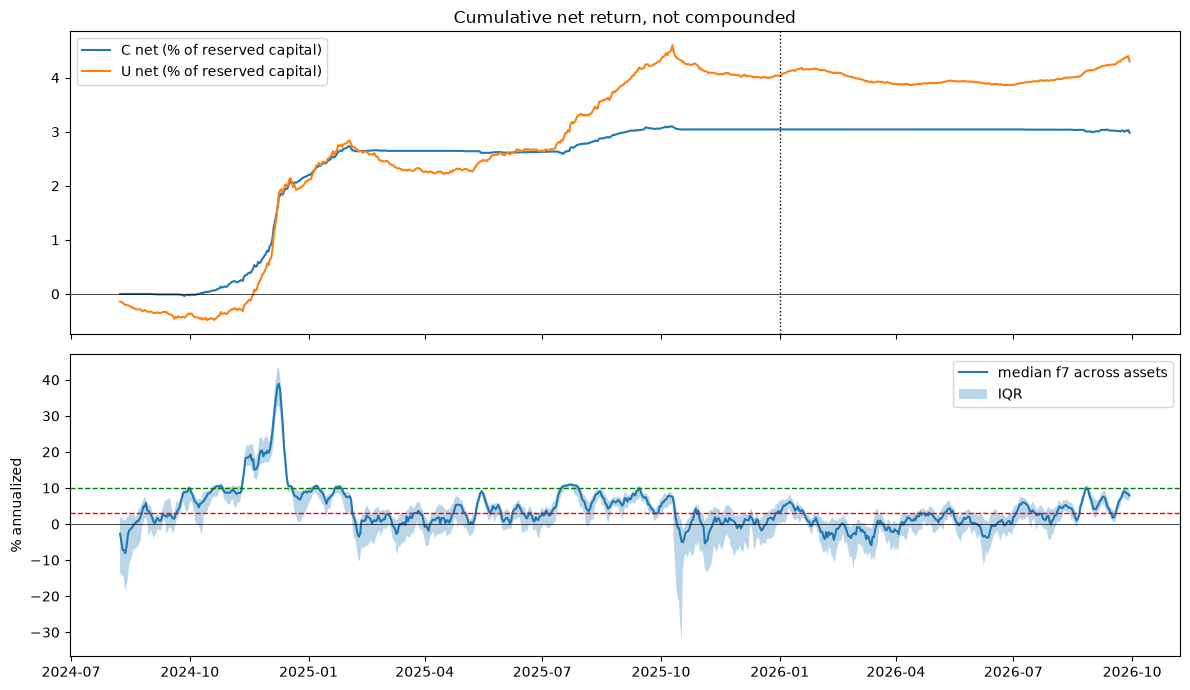

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for name in ('C', 'U'):
    p = RUNS[name][1]
    ax[0].plot(pd.to_datetime(p['b']), 100 * p['ret_reserved'].cumsum(), label=f'{name} net (% of reserved capital)')
ax[0].axvline(fc.DEV_END, c='k', ls=':', lw=1); ax[0].axhline(0, c='k', lw=.5); ax[0].legend(); ax[0].set_title('Cumulative net return, not compounded')
f7 = pd.concat({a: d.set_index('b')['f7'] for a, d in FRAMES.items()}, axis=1)
ax[1].plot(f7.index, 100 * f7.median(axis=1), label='median f7 across assets')
ax[1].fill_between(f7.index, 100 * f7.quantile(.25, axis=1), 100 * f7.quantile(.75, axis=1), alpha=.3, label='IQR')
ax[1].axhline(100 * fc.ENTRY, c='g', ls='--', lw=1); ax[1].axhline(100 * fc.EXIT, c='r', ls='--', lw=1); ax[1].axhline(0, c='k', lw=.5)
ax[1].set_ylabel('% annualized'); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / '01_equity_funding.png', dpi=110); plt.show()